# GRIDTWIN-24 — Research-grade day-ahead grid-demand forecasting

**Dataset:** [Hack Day Lucknow — P2 Grid Demand Forecast](https://github.com/CodewithJha/hack-day-lucknow-datasets/tree/main/p2-grid-demand-forecast)

This notebook is designed for Google Colab. It is deliberately more rigorous than a typical time-series tutorial: it audits the raw timestamps, catches suspicious measurements, prevents future-information leakage, benchmarks simple baselines against supervised machine learning, evaluates on rolling forecast origins, keeps a final chronological holdout, and produces the organiser's 24-row submission format.

## What the repository README says

- `history.csv`: 79,283 hourly records, from **2015-04-19 00:00** to **2024-06-16 23:00**.
- Target: `demand_mw`.
- Other columns: `generation_mw`, `load_shedding`, fuel-generation values, renewable generation and cross-border/import columns.
- Known data issues: missing hours, typo-like spikes (including an example around **121,000 MW**) and import columns that begin part-way through the timeline.
- `sample_forecast_one_origin.csv` documents the required output schema: `timestamp,demand_mw,p10,p90`.

The raw CSV is downloaded directly from the repository when this notebook runs. The GitHub connector could read the README and sample file but could not return the full 5.2 MB CSV in this chat, so **the full dataset has not been trained or benchmarked here**. All reported model metrics must come from running this notebook in Colab.

## Forecasting strategy

1. **Data integrity:** strict timestamp parsing, duplicate handling, hourly reindexing, missing-hour diagnostics and past-only spike detection.
2. **Leakage-safe features:** calendar features known in advance, target lags and rolling statistics computed only through the forecast origin, plus strictly historical lags of operational covariates.
3. **Model suite:** seasonal-naïve baselines, LightGBM and CatBoost. The primary supervised model is a pooled direct multi-horizon model: one model learns all 24 horizons using an explicit horizon feature.
4. **Evaluation:** expanding-window rolling-origin backtests. A final untouched 28-day block is held out for reporting.
5. **Uncertainty:** horizon-wise residual calibration from out-of-time predictions, with empirical coverage and interval width reported.
6. **Foundation-model challenger:** optional Chronos-2 zero-shot benchmark. It is not assumed to win; it must prove its value on the same historical origins.
7. **Final forecast:** refit the selected model on all labels available before `FORECAST_DATE` and write `sample_forecast_one_origin.csv`.

> No responsible pipeline can promise near-perfect accuracy. The objective is the strongest **honest out-of-time accuracy** that this dataset supports. A model with apparently perfect accuracy caused by future leakage is worse than a less accurate but valid model.

## Research decisions and leakage rules

**Forecast origin:** the model is assumed to issue a day-ahead forecast after the previous day has completed (23:00 in the dataset's published clock). It predicts the next 24 timestamps (00:00–23:00). The README does not specify a timezone, so timestamps are kept in their published, timezone-naïve clock; the notebook does not silently convert them to UTC.

**Operational covariates:** `generation_mw`, fuel generation, renewables, imports and `load_shedding` may be consequences of contemporaneous demand or dispatch decisions. Therefore, the supervised model may use only their values observed at or before the forecast origin (lags/rolling history). It must never use same-hour future generation or imports as future-known predictors. The notebook compares demand/calendar-only features against a history-enriched feature set to see whether these lagged covariates genuinely help.

**Missing hours:** target labels are never interpolated. Past-only imputations are allowed only when constructing historical input features, and missingness flags are added. An origin/horizon is omitted from supervised training or scoring if its target label is missing or masked as an extreme suspect.

**Outliers:** the repository explicitly warns about typo-like spikes. A causal hour-of-week baseline is used to flag extreme high values. Candidate anomalies are displayed; only extreme candidates crossing a conservative threshold are masked by default. The raw values are retained for audit. Do not remove ordinary peaks simply because they are inconvenient for a model.

**Model selection:** the final holdout is not used to tune hyperparameters or select features. Rolling validation is used for model selection; the final holdout is used once for the final performance report.

## 0. Runtime and configuration
Run all cells in order. A Colab GPU is useful only for the optional Chronos-2 challenger; LightGBM and CatBoost run on CPU.

In [ ]:
# Main dependencies. Run once in a fresh Colab runtime.
%pip -q install -U lightgbm catboost optuna joblib pyarrow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
from __future__ import annotations
import os, sys, json, math, time, hashlib, warnings, platform
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)

# ---------------- USER CONFIG ----------------
DATA_URL = "https://raw.githubusercontent.com/CodewithJha/hack-day-lucknow-datasets/main/p2-grid-demand-forecast/history.csv"
EXPECTED_GIT_BLOB_SHA = "bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e"
EXPECTED_ROWS_FROM_README = 79_283

# Set to an ISO date such as "2024-06-10" when the organisers give a forecast date.
# None means: forecast the calendar day immediately after the final dataset timestamp.
FORECAST_DATE = None

HOLDOUT_DAYS = 28
N_CV_FOLDS = 4
CV_VAL_DAYS = 21
MIN_CONTEXT_HOURS = 24 * 28

AUTO_MASK_EXTREME_SPIKES = True
SPIKE_MULTIPLIER = 3.0          # also require a large robust-MAD deviation
SPIKE_MAD_MULTIPLIER = 10.0

RUN_OPTUNA = True
N_OPTUNA_TRIALS = 8

# Optional pretrained foundation model. It is a challenger, not a dependency.
# Set True only when you have enough Colab RAM/GPU and internet access.
RUN_CHRONOS2 = False
CHRONOS2_ORIGINS_PER_FOLD = 4

OUTPUT_DIR = Path("/content/gridtwin24_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("Forecast date override:", FORECAST_DATE)

Python: 3.13.16
pandas: 2.2.3
Forecast date override: None


## 1. Download the exact dataset and verify its structure

In [ ]:
import requests

csv_path = Path("/content/history.csv")
if not csv_path.exists():
    response = requests.get(DATA_URL, timeout=120)
    response.raise_for_status()
    if len(response.content) < 1_000_000:
        raise RuntimeError(f"Downloaded file is unexpectedly small ({len(response.content):,} bytes). Check the URL.")
    csv_path.write_bytes(response.content)

blob_bytes = csv_path.read_bytes()
# Git's blob SHA-1 format: SHA1(b"blob <size>\\0" + bytes)
git_blob_sha = hashlib.sha1(b"blob " + str(len(blob_bytes)).encode() + b"\x00" + blob_bytes).hexdigest()
print(f"Downloaded: {len(blob_bytes):,} bytes")
print("Git blob SHA:", git_blob_sha)
if git_blob_sha != EXPECTED_GIT_BLOB_SHA:
    warnings.warn("Dataset SHA differs from the repository version inspected for this notebook. Re-check schema and README before proceeding.")

raw = pd.read_csv(csv_path, low_memory=False)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())

# Remove CSV-export index artefacts; do not let a row-number column become a predictor.
unnamed_cols = [c for c in raw.columns if str(c).strip().lower().startswith("unnamed:")]
if unnamed_cols:
    print("Dropping export-index artefacts:", unnamed_cols)
    raw = raw.drop(columns=unnamed_cols)

required = {"timestamp", "demand_mw"}
missing_required = required - set(raw.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")
if len(raw) != EXPECTED_ROWS_FROM_README:
    warnings.warn(f"README stated {EXPECTED_ROWS_FROM_README:,} rows; downloaded version has {len(raw):,}. Treat this as a dataset-version change.")

Downloaded: 5,240,286 bytes
Git blob SHA: bbe04aab1d83f6a0226d30c9e3cf63b7ee5db68e
Shape: (79283, 14)
Columns: ['timestamp', 'generation_mw', 'demand_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']


## 2. Timestamp, duplicate and frequency audit
This cell does not silently reinterpret timestamps. If a malformed or non-hourly timestamp exists, it is reported and the pipeline stops rather than shifting it into the wrong hour.

In [ ]:
raw = raw.copy()
raw["timestamp_raw"] = raw["timestamp"].astype(str)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], errors="coerce")

bad_ts = raw["timestamp"].isna()
print("Unparseable timestamps:", int(bad_ts.sum()))
if bad_ts.any():
    display(raw.loc[bad_ts, ["timestamp_raw"]].head(20))
    raise ValueError("Unparseable timestamps found. Fix or explicitly account for them before modelling.")

# The published dataset is hourly and timezone-naïve. Do not silently UTC-localize it.
if getattr(raw["timestamp"].dt, "tz", None) is not None:
    raise ValueError("Timezone-aware timestamps detected. Confirm the source timezone and DST policy explicitly before continuing.")

non_hour = (raw["timestamp"].dt.minute != 0) | (raw["timestamp"].dt.second != 0) | (raw["timestamp"].dt.microsecond != 0)
print("Off-hour timestamps:", int(non_hour.sum()))
if non_hour.any():
    display(raw.loc[non_hour, ["timestamp_raw", "timestamp"]].head(20))
    raise ValueError("The file contains timestamps not aligned to whole hours; do not round them silently.")

# Convert all non-timestamp columns to numeric; report coercions.
value_cols = [c for c in raw.columns if c not in ["timestamp", "timestamp_raw"]]
for c in value_cols:
    before = raw[c].notna().sum()
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
    coerced = int(before - raw[c].notna().sum())
    if coerced:
        print(f"{c}: coerced {coerced} non-numeric values to NaN")

exact_duplicate_rows = int(raw.drop(columns=["timestamp_raw"]).duplicated().sum())
raw = raw.drop_duplicates(subset=["timestamp"] + value_cols, keep="first")

# Report duplicate timestamps. Exact duplicates have now been removed.
dup_ts_mask = raw["timestamp"].duplicated(keep=False)
duplicate_timestamp_rows = int(dup_ts_mask.sum())
print("Exact duplicate rows removed:", exact_duplicate_rows)
print("Rows participating in duplicate timestamps after exact de-duplication:", duplicate_timestamp_rows)

if duplicate_timestamp_rows:
    dup_report = raw.loc[dup_ts_mask].sort_values("timestamp")
    print("Conflicting duplicate timestamp examples:")
    display(dup_report.head(20))
    # Conservative deterministic resolution: median of numeric readings at same timestamp.
    # The conflicting timestamps remain visible in the audit output above.
    raw = raw.groupby("timestamp", as_index=False)[value_cols].median()

raw = raw.drop(columns=["timestamp_raw"], errors="ignore")
raw = raw.sort_values("timestamp").set_index("timestamp")

if not raw.index.is_monotonic_increasing:
    raise RuntimeError("Timestamp sorting failed.")

full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="h", name="timestamp")
missing_hours = full_index.difference(raw.index)
extra_hours = raw.index.difference(full_index)
print("First timestamp:", raw.index.min())
print("Last timestamp:", raw.index.max())
if raw.index.min() != pd.Timestamp("2015-04-19 00:00:00"):
    warnings.warn("Dataset start differs from README (2015-04-19 00:00:00). Inspect version changes.")
if raw.index.max() != pd.Timestamp("2024-06-16 23:00:00"):
    warnings.warn("Dataset end differs from README (2024-06-16 23:00:00). This may be an updated/hidden date range; inspect before forecasting.")
print("Rows after duplicate resolution:", len(raw))
print("Expected full hourly slots:", len(full_index))
print("Missing hourly slots:", len(missing_hours))
print("Off-grid timestamps:", len(extra_hours))

hourly = raw.reindex(full_index)

# Consecutive missing-gap summary
missing_mask = hourly["demand_mw"].isna().to_numpy()
gap_lengths=[]
run=0
for v in missing_mask:
    if v: run += 1
    elif run:
        gap_lengths.append(run); run=0
if run: gap_lengths.append(run)
print("Missing-demand gap count:", len(gap_lengths))
print("Longest missing-demand gap (hours):", max(gap_lengths, default=0))
print("Gap length quantiles:", pd.Series(gap_lengths).quantile([.5,.9,.99]).to_dict() if gap_lengths else {})

Unparseable timestamps: 0
Off-hour timestamps: 0
Exact duplicate rows removed: 0
Rows participating in duplicate timestamps after exact de-duplication: 0
First timestamp: 2015-04-19 00:00:00
Last timestamp: 2024-06-16 23:00:00
Rows after duplicate resolution: 79283
Expected full hourly slots: 80328
Missing hourly slots: 1045
Off-grid timestamps: 0
Missing-demand gap count: 222
Longest missing-demand gap (hours): 517
Gap length quantiles: {0.5: 1.0, 0.9: 8.0, 0.99: 22.739999999999952}


## 3. Inspect the target and covariate coverage

Target summary:


,demand_mw
count,79283.000000
mean,8461.528739
std,2549.550226
min,6.000000
0.1%,3222.794000
1%,4094.640000
50%,8089.000000
95%,13000.000000
99%,14666.360000
99.9%,16100.000000


,non_missing,missing_pct,first_available,last_available
india_adani,0,100.000000,NaT,NaT
nepal,0,100.000000,NaT,NaT
wind,9146,88.614182,2023-06-01 06:00:00,2024-06-16 23:00:00
solar,58766,26.842446,2017-09-20 06:00:00,2024-06-16 23:00:00
generation_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00
liquid_fuel,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00
gas,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00
load_shedding,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00
demand_mw,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00
coal,79283,1.300916,2015-04-19 00:00:00,2024-06-16 23:00:00


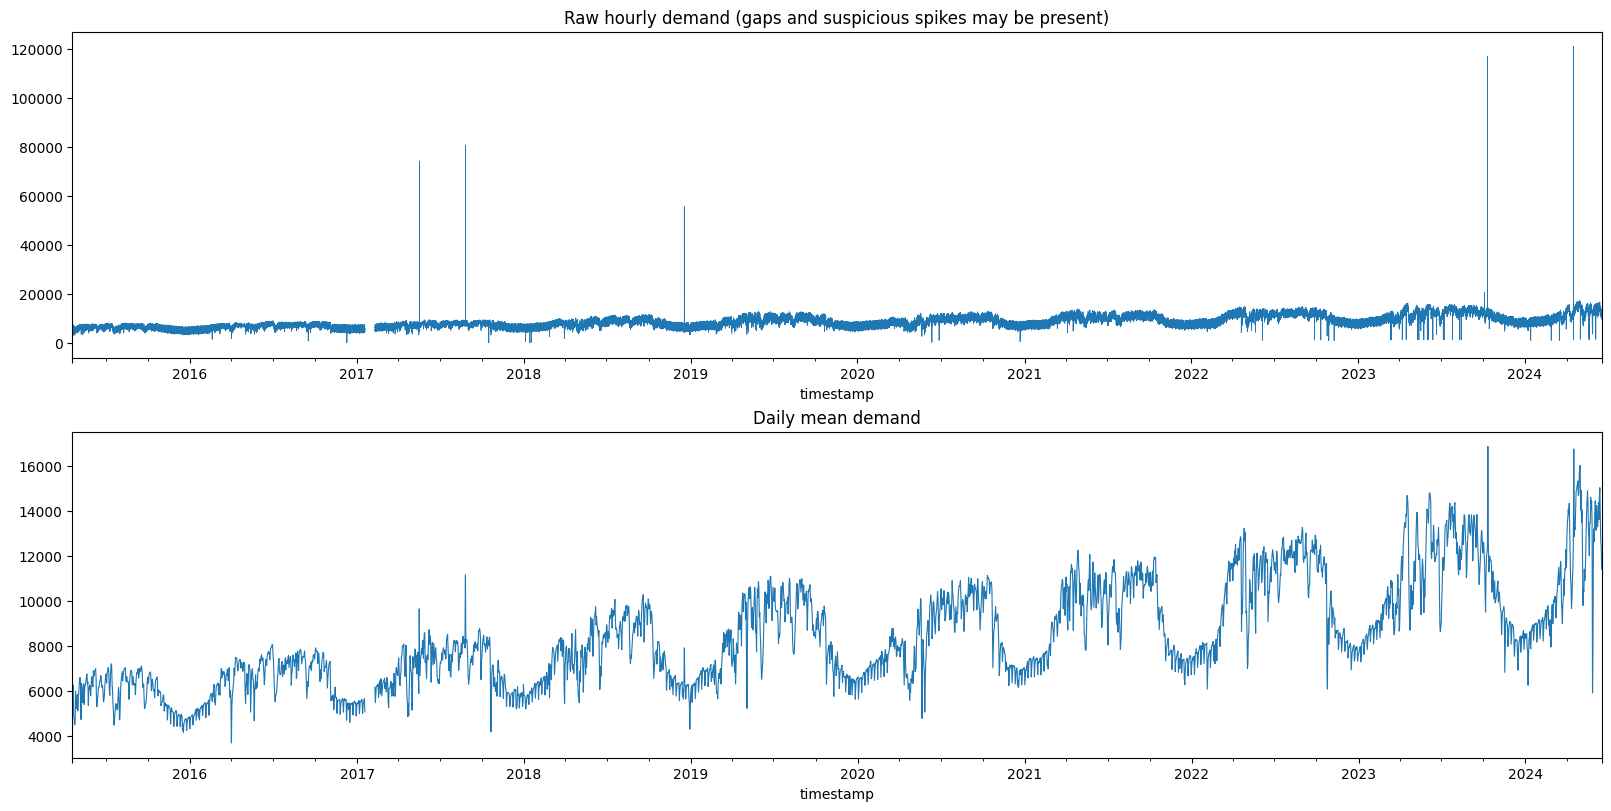

In [ ]:
print("Target summary:")
display(hourly["demand_mw"].describe(percentiles=[.001,.01,.5,.95,.99,.999]).to_frame())

coverage = pd.DataFrame({
    "non_missing": hourly.notna().sum(),
    "missing_pct": 100*hourly.isna().mean(),
    "first_available": [hourly[c].first_valid_index() for c in hourly.columns],
    "last_available": [hourly[c].last_valid_index() for c in hourly.columns],
})
display(coverage.sort_values("missing_pct", ascending=False))

fig, ax = plt.subplots(2, 1, figsize=(16, 8), constrained_layout=True)
hourly["demand_mw"].plot(ax=ax[0], lw=.55, title="Raw hourly demand (gaps and suspicious spikes may be present)")
hourly["demand_mw"].resample("D").mean().plot(ax=ax[1], lw=.8, title="Daily mean demand")
plt.show()

## 4. Causal anomaly audit — catch typo-like spikes without erasing real peaks
The seasonal reference for each hour-of-week uses only earlier observations from that same hour-of-week. It never uses future rows to decide whether a past value is anomalous.

Extreme high candidates: 5
Negative target values: 0
Zero/nonpositive target values: 0


,demand_mw_raw,past_hour_of_week_median,past_robust_sigma,upper_threshold,extreme_high_candidate,negative_value,nonpositive_value
timestamp,,,,,,,
2017-05-17 12:00:00,74223.0,6756.0,1045.2330,20268.000,True,False,False
2017-08-26 15:00:00,80689.0,7727.0,1123.0695,23181.000,True,False,False
2018-12-18 08:00:00,55639.0,7366.0,1659.0294,23956.294,True,False,False
2023-10-11 03:00:00,117000.0,12550.0,1675.3380,37650.000,True,False,False
2024-04-16 07:00:00,121000.0,8925.0,1451.4654,26775.000,True,False,False


Target labels masked: 5


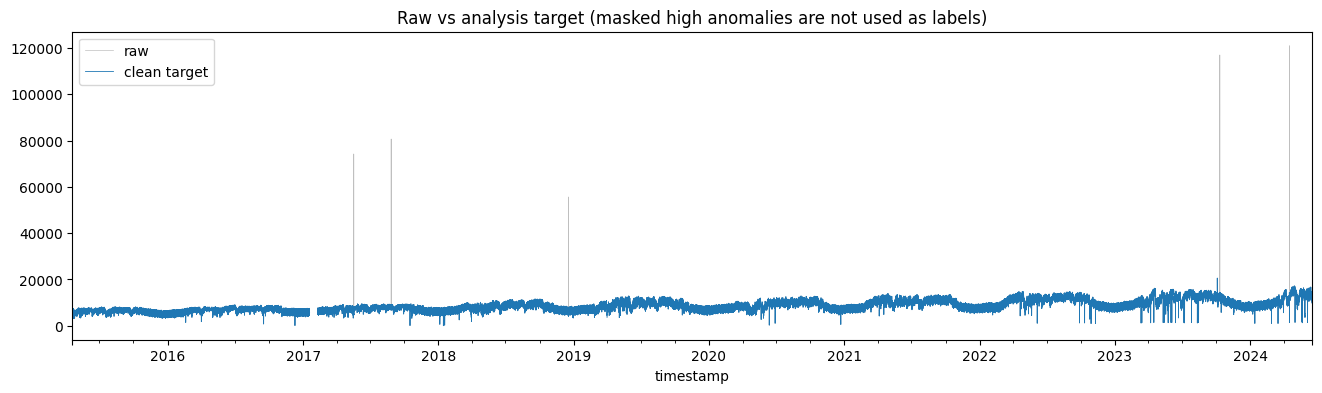

In [ ]:
y_raw = hourly["demand_mw"].astype(float).copy()

how = pd.Series(hourly.index.dayofweek*24 + hourly.index.hour, index=hourly.index)

def _past_group_median(s):
    return s.shift(1).rolling(20, min_periods=8).median()

def _past_group_mad(s):
    past = s.shift(1)
    med = past.rolling(20, min_periods=8).median()
    return (past-med).abs().rolling(20, min_periods=8).median()

seasonal_med = y_raw.groupby(how).transform(_past_group_median)
seasonal_mad = y_raw.groupby(how).transform(_past_group_mad)
robust_sigma = 1.4826 * seasonal_mad

# Fallback only when fewer than eight prior matching hour-of-week observations exist.
expanding_med = y_raw.expanding(min_periods=24*7).median().shift(1)
seasonal_med = seasonal_med.fillna(expanding_med)
seasonal_mad = seasonal_mad.fillna((y_raw-expanding_med).abs().expanding(min_periods=24*7).median().shift(1))

upper_threshold = np.maximum(
    seasonal_med * SPIKE_MULTIPLIER,
    seasonal_med + SPIKE_MAD_MULTIPLIER * robust_sigma.fillna(0)
)

invalid_negative = y_raw < 0
extreme_high = y_raw.notna() & seasonal_med.notna() & (y_raw > upper_threshold)
zero_or_nonpositive = y_raw.notna() & (y_raw <= 0)

anomaly_table = pd.DataFrame({
    "demand_mw_raw": y_raw,
    "past_hour_of_week_median": seasonal_med,
    "past_robust_sigma": robust_sigma,
    "upper_threshold": upper_threshold,
    "extreme_high_candidate": extreme_high,
    "negative_value": invalid_negative,
    "nonpositive_value": zero_or_nonpositive,
})
print("Extreme high candidates:", int(extreme_high.sum()))
print("Negative target values:", int(invalid_negative.sum()))
print("Zero/nonpositive target values:", int(zero_or_nonpositive.sum()))
display(anomaly_table.loc[extreme_high | invalid_negative | zero_or_nonpositive].head(100))

# Keep raw values for audit; build a cleaned target used as labels.
y_clean = y_raw.copy()
y_clean.loc[invalid_negative] = np.nan
if AUTO_MASK_EXTREME_SPIKES:
    y_clean.loc[extreme_high] = np.nan

# Do not automatically mask zero values: they are flagged for review but retained unless negative.
print("Target labels masked:", int(y_clean.isna().sum() - y_raw.isna().sum()))
fig, ax = plt.subplots(figsize=(16,4))
y_raw.plot(ax=ax, color="0.75", lw=.5, label="raw")
y_clean.plot(ax=ax, lw=.6, label="clean target")
ax.set_title("Raw vs analysis target (masked high anomalies are not used as labels)")
ax.legend(); plt.show()

## 5. Past-only imputation and feature design
Target labels are never imputed. The feature history may use only values available before the origin: short forward-fill, then the same hour one week earlier, then a trailing expanding median. Missingness counts tell the model when input data was incomplete.

In [ ]:
# Past-only target feature series. No bfill, centred rolling window, or full-series interpolation.
y_feature = y_clean.ffill(limit=3)
y_feature = y_feature.fillna(y_clean.shift(168))
y_feature = y_feature.fillna(y_clean.expanding(min_periods=24*7).median().shift(1))

# Remaining leading NaNs are expected during the initial warm-up period.
missing_y = y_clean.isna().astype(float)
rolling_y = {
    "y__roll_mean_6": y_feature.rolling(6, min_periods=4).mean(),
    "y__roll_std_6": y_feature.rolling(6, min_periods=4).std(),
    "y__roll_mean_24": y_feature.rolling(24, min_periods=18).mean(),
    "y__roll_std_24": y_feature.rolling(24, min_periods=18).std(),
    "y__roll_min_24": y_feature.rolling(24, min_periods=18).min(),
    "y__roll_max_24": y_feature.rolling(24, min_periods=18).max(),
    "y__roll_mean_168": y_feature.rolling(168, min_periods=120).mean(),
    "y__roll_std_168": y_feature.rolling(168, min_periods=120).std(),
    "y__roll_mean_336": y_feature.rolling(336, min_periods=240).mean(),
    "y__missing_24": missing_y.rolling(24, min_periods=1).sum(),
    "y__missing_168": missing_y.rolling(168, min_periods=1).sum(),
}

EXOG_ALLOWLIST = [
    "generation_mw", "load_shedding", "gas", "liquid_fuel", "coal", "hydro", "solar", "wind",
    "india_bheramara_hvdc", "india_tripura", "india_adani", "nepal",
]
EXOG_COLS = [c for c in EXOG_ALLOWLIST if c in hourly.columns and pd.api.types.is_numeric_dtype(hourly[c])]
unexpected_numeric = [c for c in hourly.columns if c not in ["demand_mw"] + EXOG_ALLOWLIST and pd.api.types.is_numeric_dtype(hourly[c])]
if unexpected_numeric:
    print("Unrecognised numeric columns excluded from predictors (inspect manually):", unexpected_numeric)
exog_series = {}
exog_roll = {}
for c in EXOG_COLS:
    s = hourly[c].replace([np.inf, -np.inf], np.nan).astype(float)
    # Only short forward-fill; longer unavailable periods remain NaN for tree models.
    s_ff = s.ffill(limit=3)
    exog_series[c] = s_ff
    safe = c.replace(" ", "_")
    exog_roll[f"x__{safe}__mean24"] = s_ff.rolling(24, min_periods=6).mean()
    exog_roll[f"x__{safe}__mean168"] = s_ff.rolling(168, min_periods=24).mean()
    exog_roll[f"x__{safe}__missing24"] = s.isna().rolling(24, min_periods=1).sum()

print("Historical covariates:", EXOG_COLS)
print("Base target feature series remaining NaN:", int(y_feature.isna().sum()))

Historical covariates: ['generation_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal']
Base target feature series remaining NaN: 11


## 6. Build pooled direct 24-horizon supervised examples
Each row represents one `(forecast_origin, horizon)` pair. The model sees only data available at the origin plus calendar facts known for the target hour. This avoids recursive error accumulation and prevents the model from seeing future generation/dispatch measurements.

In [ ]:
LAGS = [1,2,3,6,12,24,48,72,168,336,504,672]

def calendar_features(ts: pd.Timestamp) -> dict:
    hour = ts.hour
    dow = ts.dayofweek
    doy = ts.dayofyear
    month = ts.month
    return {
        "horizon": None,
        "cal__hour": hour,
        "cal__hour_sin": np.sin(2*np.pi*hour/24),
        "cal__hour_cos": np.cos(2*np.pi*hour/24),
        "cal__dow": dow,
        "cal__dow_sin": np.sin(2*np.pi*dow/7),
        "cal__dow_cos": np.cos(2*np.pi*dow/7),
        "cal__doy_sin": np.sin(2*np.pi*doy/365.25),
        "cal__doy_cos": np.cos(2*np.pi*doy/365.25),
        "cal__month_sin": np.sin(2*np.pi*(month-1)/12),
        "cal__month_cos": np.cos(2*np.pi*(month-1)/12),
        "cal__is_weekend": int(dow >= 5),
        "cal__year_trend": (ts - hourly.index[0]).total_seconds()/(86400*365.25),
    }

def _v(series: pd.Series, pos: int):
    if pos < 0 or pos >= len(series):
        return np.nan
    return series.iloc[pos]

def make_origin_rows(origin: pd.Timestamp, include_y: bool = True) -> list:
    """Create 24 target-hour rows. Every historical feature is indexed at/before origin."""
    if origin not in hourly.index:
        raise ValueError(f"Origin {origin} is not on the hourly index")
    op = hourly.index.get_loc(origin)
    if not isinstance(op, (int, np.integer)):
        raise ValueError("Origin index is not unique after duplicate handling")
    if op < MIN_CONTEXT_HOURS:
        raise ValueError("Not enough history before forecast origin")

    rows=[]
    for h in range(1,25):
        tp = op+h
        if tp >= len(hourly.index):
            # Used for final future prediction; future timestamps may be beyond the index.
            target_ts = origin + pd.Timedelta(hours=h)
        else:
            target_ts = hourly.index[tp]

        row = {"origin_ts": origin, "target_ts": target_ts, "horizon": h}
        row.update(calendar_features(target_ts))
        row["horizon"] = h

        for lag in LAGS:
            row[f"y__lag_{lag}"] = _v(y_feature, op-lag+1)  # last value is at origin for lag=1
        # Same target clock-hour from yesterday and last week; both are known by the origin.
        row["y__same_hour_yesterday"] = _v(y_feature, op+h-24)
        row["y__same_hour_lastweek"] = _v(y_feature, op+h-168)
        row["y__same_hour_2weeks"] = _v(y_feature, op+h-336)
        for name, series in rolling_y.items():
            row[name] = _v(series, op)

        # Only past exogenous values. No exogenous value at target_ts is used.
        for c, s in exog_series.items():
            safe = c.replace(" ", "_")
            row[f"x__{safe}__last"] = _v(s, op)
            row[f"x__{safe}__lag24"] = _v(s, op-24)
            row[f"x__{safe}__lag168"] = _v(s, op-168)
            row[f"x__{safe}__mean24"] = _v(exog_roll[f"x__{safe}__mean24"], op)
            row[f"x__{safe}__mean168"] = _v(exog_roll[f"x__{safe}__mean168"], op)
            row[f"x__{safe}__missing24"] = _v(exog_roll[f"x__{safe}__missing24"], op)

        if include_y:
            if tp >= len(hourly.index):
                continue
            label = y_clean.iloc[tp]
            if pd.isna(label):
                continue
            row["y"] = float(label)
        rows.append(row)
    return rows

# Day-ahead origin: 23:00, forecasting the following calendar day 00:00..23:00.
all_origins = hourly.index[(hourly.index.hour == 23)]
all_origins = [o for o in all_origins if hourly.index.get_loc(o) + 24 < len(hourly.index)]
all_origins = [o for o in all_origins if hourly.index.get_loc(o) >= MIN_CONTEXT_HOURS]

records=[]
for i, origin in enumerate(all_origins):
    records.extend(make_origin_rows(origin, include_y=True))
    if (i+1) % 500 == 0:
        print(f"Built examples for {i+1:,}/{len(all_origins):,} origins")

samples = pd.DataFrame(records)
samples = samples.sort_values(["origin_ts", "horizon"]).reset_index(drop=True)
print("Supervised rows:", samples.shape)
print("Unique origins:", samples["origin_ts"].nunique())
print("Label coverage:", samples["y"].notna().mean())

META_COLS = ["origin_ts", "target_ts", "horizon", "y"]
CAL_FEATURES = [c for c in samples.columns if c.startswith("cal__")]
Y_FEATURES = [c for c in samples.columns if c.startswith("y__")]
X_FEATURES = [c for c in samples.columns if c.startswith("x__")]
BASE_FEATURES = ["horizon"] + CAL_FEATURES + Y_FEATURES
CONTEXT_FEATURES = BASE_FEATURES + X_FEATURES
print("Demand/calendar feature count:", len(BASE_FEATURES))
print("Context feature count:", len(CONTEXT_FEATURES))

Built examples for 500/3,318 origins
Built examples for 1,000/3,318 origins
Built examples for 1,500/3,318 origins
Built examples for 2,000/3,318 origins
Built examples for 2,500/3,318 origins
Built examples for 3,000/3,318 origins
Supervised rows: (78669, 114)
Unique origins: 3297
Label coverage: 1.0
Demand/calendar feature count: 39
Context feature count: 111


## 7. Leakage tests and date-boundary checks
The key test: changing any value strictly after a forecast origin must not change the feature rows generated for that origin.

In [ ]:
# Verify that the constructed feature rows use only timestamps at/before the origin.
# This test is structural: the feature constructor only indexes y/exogenous series at op or earlier.
_test_origin = all_origins[-100]
_test_rows_before = pd.DataFrame(make_origin_rows(_test_origin, include_y=False))

# Make a copy of all underlying series, perturb data after origin, and verify the origin features are unchanged.
# In-place temporary mutation is restored immediately.
_future_mask = hourly.index > _test_origin
_backup_y = y_feature.copy()
_backup_exog = {k:v.copy() for k,v in exog_series.items()}
try:
    y_feature.loc[_future_mask] = 1e15
    for k in exog_series:
        exog_series[k].loc[_future_mask] = -1e15
    _test_rows_after = pd.DataFrame(make_origin_rows(_test_origin, include_y=False))
finally:
    y_feature = _backup_y
    exog_series = _backup_exog

compare_cols = [c for c in _test_rows_before.columns if c not in ["origin_ts", "target_ts"]]
assert np.allclose(_test_rows_before[compare_cols].to_numpy(float), _test_rows_after[compare_cols].to_numpy(float), equal_nan=True)
print("PASS: future-value perturbation does not change features at the selected origin.")

# Check that labels do not include the forecast origin or earlier observations.
assert (samples["target_ts"] > samples["origin_ts"]).all()
assert samples["horizon"].between(1,24).all()
print("PASS: every supervised label is strictly after its forecast origin and horizon is 1..24.")

PASS: future-value perturbation does not change features at the selected origin.
PASS: every supervised label is strictly after its forecast origin and horizon is 1..24.


## 8. Define the requested forecast date
For an ISO date such as `2024-06-10`, the forecast origin is the previous day at 23:00. If the date is omitted, we forecast the day immediately after the dataset ends.

In [ ]:
last_ts = hourly.index.max()
if FORECAST_DATE is None:
    forecast_day = last_ts.normalize() + pd.Timedelta(days=1)
else:
    forecast_day = pd.Timestamp(FORECAST_DATE).normalize()
forecast_origin = forecast_day - pd.Timedelta(hours=1)

if forecast_origin < hourly.index.min() + pd.Timedelta(hours=MIN_CONTEXT_HOURS):
    raise ValueError("Forecast date is too early; there is not enough lookback history.")
if forecast_origin > last_ts:
    raise ValueError(
        f"Forecast origin {forecast_origin} is after last available observation {last_ts}. "
        "The dataset does not contain the history needed for this date."
    )
if forecast_origin not in hourly.index:
    raise ValueError("Forecast origin is not present in the reindexed hourly timeline.")

print("Last data timestamp:", last_ts)
print("Forecast date:", forecast_day.date())
print("Forecast origin:", forecast_origin)
print("Most recent 24-hour target missing count:", int(y_clean.loc[forecast_origin-pd.Timedelta(hours=23):forecast_origin].isna().sum()))

# Eligible past forecast origins are those strictly before the requested origin and with target rows already observed by it.
eligible_origins = sorted([o for o in all_origins if o < forecast_origin])
if len(eligible_origins) <= HOLDOUT_DAYS + N_CV_FOLDS*CV_VAL_DAYS:
    raise ValueError("Insufficient historical origins for the requested holdout and CV settings.")

# Holdout: final chronological HOLDOUT_DAYS day-ahead origins available before the requested forecast origin.
holdout_origins = eligible_origins[-HOLDOUT_DAYS:]
pre_holdout_origins = eligible_origins[:-HOLDOUT_DAYS]
holdout_start_origin = holdout_origins[0]
print("Historical holdout origins:", holdout_origins[0], "through", holdout_origins[-1], f"({len(holdout_origins)} days)")
print("Holdout labels stop before/at requested origin:", forecast_origin)

Last data timestamp: 2024-06-16 23:00:00
Forecast date: 2024-06-17
Forecast origin: 2024-06-16 23:00:00
Most recent 24-hour target missing count: 0
Historical holdout origins: 2024-05-19 23:00:00 through 2024-06-15 23:00:00 (28 days)
Holdout labels stop before/at requested origin: 2024-06-16 23:00:00


## 9. Rolling-origin validation folds
Each validation block is a sequence of daily forecast origins. For a validation origin, model training labels are restricted to timestamps at or before that origin. Validation forecasts later in the block may use newly observed actual values in their lag features, matching daily operations.

In [ ]:
def build_rolling_folds(origins, n_splits=4, val_days=21):
    origins = list(origins)
    required = n_splits * val_days
    if len(origins) < required + 30:
        raise ValueError("Not enough pre-holdout origins for requested rolling folds.")
    start = len(origins) - required
    folds=[]
    for k in range(n_splits):
        a = start + k*val_days
        b = a + val_days
        val_origins = origins[a:b]
        folds.append({"name": f"fold_{k+1}", "val_origins": val_origins, "val_start": val_origins[0]})
    return folds

folds = build_rolling_folds(pre_holdout_origins, N_CV_FOLDS, CV_VAL_DAYS)
for f in folds:
    print(f["name"], f["val_origins"][0], "to", f["val_origins"][-1], "n=", len(f["val_origins"]))

fold_1 2024-02-25 23:00:00 to 2024-03-16 23:00:00 n= 21
fold_2 2024-03-17 23:00:00 to 2024-04-06 23:00:00 n= 21
fold_3 2024-04-07 23:00:00 to 2024-04-27 23:00:00 n= 21
fold_4 2024-04-28 23:00:00 to 2024-05-18 23:00:00 n= 21


## 10. Metrics and honest baselines

In [ ]:
def forecast_metrics(y_true, y_pred):
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    m = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[m], yp[m]
    if len(yt) == 0:
        return {"n":0,"MAE":np.nan,"RMSE":np.nan,"WAPE_pct":np.nan,"sMAPE_pct":np.nan,"Bias":np.nan}
    err = yp-yt
    denom = np.sum(np.abs(yt))
    sm_denom = np.maximum(np.abs(yt)+np.abs(yp), 1e-9)
    return {
        "n": int(len(yt)),
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err**2))),
        "WAPE_pct": float(100*np.sum(np.abs(err))/denom) if denom else np.nan,
        "sMAPE_pct": float(100*np.mean(2*np.abs(err)/sm_denom)),
        "Bias": float(np.mean(err)),
    }

def add_baselines(frame):
    out = frame.copy()
    out["pred_seasonal_week"] = out["y__same_hour_lastweek"]
    out["pred_seasonal_day"] = out["y__same_hour_yesterday"]
    out["pred_blend_day_week"] = 0.5*out["pred_seasonal_day"] + 0.5*out["pred_seasonal_week"]
    return out

baseline_test = add_baselines(samples)
for c in ["pred_seasonal_week", "pred_seasonal_day", "pred_blend_day_week"]:
    print(c, forecast_metrics(baseline_test["y"], baseline_test[c]))

pred_seasonal_week {'n': 78669, 'MAE': 791.5471405509159, 'RMSE': 1243.5607791878947, 'WAPE_pct': 9.336347665959787, 'sMAPE_pct': 9.405022542684629, 'Bias': -13.317291436270958}
pred_seasonal_day {'n': 78669, 'MAE': 539.1787108009509, 'RMSE': 881.399430295873, 'WAPE_pct': 6.3596463687785345, 'sMAPE_pct': 6.739685797827644, 'Bias': -1.0972555898765715}
pred_blend_day_week {'n': 78669, 'MAE': 552.8712580559052, 'RMSE': 868.2075991466007, 'WAPE_pct': 6.521150813751782, 'sMAPE_pct': 6.661837447548812, 'Bias': -7.207273513073765}


## 11. Model definitions: LightGBM and CatBoost
These are supervised pooled direct models. `horizon` and target-hour calendar features allow one estimator to learn all 24 forecast steps. Models are trained on `demand_mw` labels; no future generation/import values are used.

In [ ]:
N_JOBS = max(1, min(4, os.cpu_count() or 2))

BASE_LGB_PARAMS = dict(
    objective="regression_l1",
    n_estimators=750,
    learning_rate=0.035,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,
    reg_alpha=0.2,
    reg_lambda=5.0,
    random_state=SEED,
    n_jobs=N_JOBS,
    verbosity=-1,
)

BASE_CAT_PARAMS = dict(
    iterations=500,
    depth=6,
    learning_rate=0.035,
    loss_function="MAE",
    eval_metric="MAE",
    l2_leaf_reg=5.0,
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=N_JOBS,
)

CANDIDATES = {
    "lgbm_demand": ("lgbm", "demand"),
    "lgbm_context": ("lgbm", "context"),
    "cat_demand": ("cat", "demand"),
    "cat_context": ("cat", "context"),
}

def feature_list(kind):
    return BASE_FEATURES if kind == "demand" else CONTEXT_FEATURES

def fit_candidate(algo, features, train_df, params=None):
    X = train_df[features].replace([np.inf, -np.inf], np.nan)
    y = train_df["y"].astype(float)
    # Drop columns that are completely unavailable in this training fold.
    used = [c for c in features if X[c].notna().any() and X[c].nunique(dropna=True) > 1]
    if not used:
        raise ValueError("No usable training features remain.")
    X = X[used]
    if algo == "lgbm":
        p = BASE_LGB_PARAMS.copy(); p.update(params or {})
        model = LGBMRegressor(**p)
    elif algo == "cat":
        p = BASE_CAT_PARAMS.copy(); p.update(params or {})
        model = CatBoostRegressor(**p)
    else:
        raise ValueError(algo)
    model.fit(X, y)
    return model, used

def predict_candidate(model, used_features, frame):
    X = frame[used_features].replace([np.inf, -np.inf], np.nan)
    pred = np.asarray(model.predict(X), dtype=float)
    return np.maximum(pred, 0.0)

## 12. Rolling-origin model comparison
This is the principal model-selection experiment. Every fold trains only on labels that would already have been observed at the first validation origin. The final 28-day holdout is not touched here.

In [14]:
cv_prediction_frames = []
fold_summary = []

for fold in folds:
    val_origins = set(fold["val_origins"])
    val_start = fold["val_start"]
    train_df = samples.loc[samples["target_ts"] <= val_start].copy()
    val_df = samples.loc[samples["origin_ts"].isin(val_origins)].copy()
    print(f"\n{fold['name']}: train rows={len(train_df):,}, validation rows={len(val_df):,}")

    # Baseline OOF predictions
    val_b = add_baselines(val_df)
    for name, col in [("seasonal_week","pred_seasonal_week"),("seasonal_day","pred_seasonal_day"),("baseline_blend","pred_blend_day_week")]:
        m = forecast_metrics(val_b["y"], val_b[col])
        fold_summary.append({"fold":fold["name"],"model":name,**m})
        tmp = val_b[["origin_ts","target_ts","horizon","y"]].copy()
        tmp["model"] = name; tmp["y_pred"] = val_b[col].values
        cv_prediction_frames.append(tmp)

    for key, (algo, kind) in CANDIDATES.items():
        feats = feature_list(kind)
        model, used = fit_candidate(algo, feats, train_df)
        pred = predict_candidate(model, used, val_df)
        m = forecast_metrics(val_df["y"], pred)
        fold_summary.append({"fold":fold["name"],"model":key,**m})
        tmp = val_df[["origin_ts","target_ts","horizon","y"]].copy()
        tmp["model"] = key; tmp["y_pred"] = pred
        cv_prediction_frames.append(tmp)
        print(key, "MAE", round(m["MAE"],3), "WAPE", round(m["WAPE_pct"],3))

cv_predictions = pd.concat(cv_prediction_frames, ignore_index=True)
cv_results = pd.DataFrame(fold_summary)
cv_leaderboard = (cv_results.groupby("model")
                  .agg(mean_MAE=("MAE","mean"), mean_RMSE=("RMSE","mean"), mean_WAPE_pct=("WAPE_pct","mean"), mean_sMAPE_pct=("sMAPE_pct","mean"), total_scored=("n","sum"))
                  .sort_values(["mean_WAPE_pct","mean_MAE"]))
display(cv_leaderboard)


fold_1: train rows=75,985, validation rows=504
lgbm_demand MAE 352.163 WAPE 3.499
lgbm_context MAE 369.347 WAPE 3.67
cat_demand MAE 363.868 WAPE 3.615
cat_context MAE 344.349 WAPE 3.421

fold_2: train rows=76,489, validation rows=503
lgbm_demand MAE 575.879 WAPE 4.909
lgbm_context MAE 595.71 WAPE 5.078
cat_demand MAE 590.57 WAPE 5.034
cat_context MAE 614.564 WAPE 5.238

fold_3: train rows=76,992, validation rows=502
lgbm_demand MAE 708.005 WAPE 5.416
lgbm_context MAE 743.19 WAPE 5.685
cat_demand MAE 748.13 WAPE 5.723
cat_context MAE 733.571 WAPE 5.611

fold_4: train rows=77,494, validation rows=504
lgbm_demand MAE 893.428 WAPE 6.859
lgbm_context MAE 896.989 WAPE 6.887
cat_demand MAE 899.56 WAPE 6.907
cat_context MAE 912.73 WAPE 7.008


,mean_MAE,mean_RMSE,mean_WAPE_pct,mean_sMAPE_pct,total_scored
model,,,,,
lgbm_demand,632.368720,981.014091,5.170774,5.513920,2013
cat_demand,650.532154,999.671925,5.319660,5.665482,2013
cat_context,651.303614,1006.860504,5.319743,5.678104,2013
lgbm_context,651.308902,994.005949,5.329839,5.668021,2013
seasonal_day,812.411865,1231.252457,6.738230,7.448687,2013
baseline_blend,1203.395102,1522.699851,9.844880,10.461009,2013
seasonal_week,1971.259969,2378.749268,16.029528,17.035182,2013


## 13. Optional Optuna tuning for the best LightGBM feature view
Tuning uses rolling validation folds only. The final holdout remains untouched. The search is intentionally compact; increase `N_OPTUNA_TRIALS` only if Colab runtime permits.

In [15]:
# Tune the better of the two fixed LightGBM variants if it is competitive.
lightgbm_rank = cv_leaderboard.loc[[x for x in cv_leaderboard.index if x.startswith("lgbm_")]] if any(x.startswith("lgbm_") for x in cv_leaderboard.index) else pd.DataFrame()
tuned_model_key = None
tuned_params = None

if RUN_OPTUNA and len(lightgbm_rank):
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tuned_model_key = lightgbm_rank.index[0]
    tuned_kind = CANDIDATES[tuned_model_key][1]
    tuned_features = feature_list(tuned_kind)
    search_folds = folds[-min(2, len(folds)):]

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 300, 1000),
            "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.08, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 15, 63),
            "max_depth": trial.suggest_int("max_depth", 4, 10),
            "min_child_samples": trial.suggest_int("min_child_samples", 25, 140),
            "subsample": trial.suggest_float("subsample", 0.70, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.70, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.5, 20.0, log=True),
        }
        scores=[]
        for f in search_folds:
            v_origins=set(f["val_origins"]); v_start=f["val_start"]
            tr=samples.loc[samples["target_ts"] <= v_start]
            va=samples.loc[samples["origin_ts"].isin(v_origins)]
            m, used = fit_candidate("lgbm", tuned_features, tr, params=params)
            p = predict_candidate(m, used, va)
            scores.append(forecast_metrics(va["y"],p)["WAPE_pct"])
        return float(np.mean(scores))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
    tuned_params = study.best_params
    print("Tuned candidate:", tuned_model_key)
    print("Best rolling validation WAPE:", study.best_value)
    print("Best parameters:", tuned_params)
else:
    print("Optuna skipped (disabled or no LightGBM candidate).")

  0%|          | 0/8 [00:00<?, ?it/s]

Tuned candidate: lgbm_demand
Best rolling validation WAPE: 6.104603737531617
Best parameters: {'n_estimators': 660, 'learning_rate': 0.040436717785401505, 'num_leaves': 17, 'max_depth': 8, 'min_child_samples': 44, 'subsample': 0.7195154778955838, 'colsample_bytree': 0.984665661176, 'reg_alpha': 3.447275228705856, 'reg_lambda': 9.864408593146953}


## 14. Re-evaluate tuned LightGBM on all CV folds and build OOF predictions

In [ ]:
if tuned_model_key is not None and tuned_params is not None:
    tuned_kind = CANDIDATES[tuned_model_key][1]
    tuned_features = feature_list(tuned_kind)
    tuned_oof=[]
    for fold in folds:
        v_origins=set(fold["val_origins"]); v_start=fold["val_start"]
        tr=samples.loc[samples["target_ts"] <= v_start]
        va=samples.loc[samples["origin_ts"].isin(v_origins)]
        m, used = fit_candidate("lgbm", tuned_features, tr, params=tuned_params)
        p = predict_candidate(m, used, va)
        t=va[["origin_ts","target_ts","horizon","y"]].copy()
        t["model"]="lgbm_tuned"; t["y_pred"]=p
        tuned_oof.append(t)
    tuned_oof=pd.concat(tuned_oof,ignore_index=True)
    cv_predictions=pd.concat([cv_predictions,tuned_oof],ignore_index=True)
    display(pd.DataFrame([{"model":"lgbm_tuned",**forecast_metrics(tuned_oof.y,tuned_oof.y_pred)}]))

## 15. Select a model or validation-weighted ensemble
Selection and blend weights use only out-of-time CV predictions. The final holdout is still untouched.

In [17]:
# Compute pooled OOF metrics for all candidates.
oof_metrics=[]
for model_name, g in cv_predictions.groupby("model"):
    mm=forecast_metrics(g["y"],g["y_pred"])
    oof_metrics.append({"model":model_name,**mm})
oof_leaderboard=pd.DataFrame(oof_metrics).sort_values(["WAPE_pct","MAE"])
display(oof_leaderboard)

# Pick top two candidates with complete OOF keys, then optimize a convex blend weight.
wide = cv_predictions.pivot_table(index=["origin_ts","target_ts","horizon","y"], columns="model", values="y_pred", aggfunc="first").reset_index()
model_cols=[c for c in wide.columns if c not in ["origin_ts","target_ts","horizon","y"]]
ranked_models = list(oof_leaderboard["model"])
selected_models=[]
for m in ranked_models:
    if wide[m].notna().all():
        selected_models.append(m)
    if len(selected_models)==2:
        break

if not selected_models:
    raise RuntimeError("No candidate has complete rolling validation predictions.")

if len(selected_models)==1:
    ensemble_weights={selected_models[0]:1.0}
else:
    m1,m2=selected_models
    best_w=None; best_score=np.inf
    for w in np.linspace(0,1,41):
        p=w*wide[m1].values+(1-w)*wide[m2].values
        score=forecast_metrics(wide["y"],p)["WAPE_pct"]
        if score<best_score:
            best_score=score; best_w=w
    if best_w <= 0.05:
        ensemble_weights={m2:1.0}
    elif best_w >= 0.95:
        ensemble_weights={m1:1.0}
    else:
        ensemble_weights={m1:float(best_w),m2:float(1-best_w)}

print("Selected validation blend:", ensemble_weights)
wide["y_pred_selected"] = sum(wide[m]*w for m,w in ensemble_weights.items())
print("Selected OOF metrics:", forecast_metrics(wide.y, wide.y_pred_selected))

,model,n,MAE,RMSE,WAPE_pct,sMAPE_pct,Bias
5,lgbm_tuned,2013,631.006411,1025.785328,5.270470,5.517704,36.090405
4,lgbm_demand,2013,632.321635,1017.304817,5.281455,5.514037,17.243060
2,cat_demand,2013,650.464974,1033.213482,5.432997,5.665423,5.387877
1,cat_context,2013,651.240129,1044.496608,5.439471,5.678068,48.878628
3,lgbm_context,2013,651.245235,1029.650792,5.439514,5.668030,51.363060
6,seasonal_day,2013,812.488326,1262.641527,6.786294,7.449959,-45.035768
0,baseline_blend,2013,1203.221808,1582.141937,10.049888,10.460174,-216.208892
7,seasonal_week,2013,1970.867362,2496.634573,16.461634,17.032654,-387.382017


Selected validation blend: {'lgbm_tuned': 0.5750000000000001, 'lgbm_demand': 0.42499999999999993}
Selected OOF metrics: {'n': 2013, 'MAE': 629.1546105314173, 'RMSE': 1019.6814569237041, 'WAPE_pct': 5.2550024789807, 'sMAPE_pct': 5.493608207314547, 'Bias': 28.080283421443905}


## 16. Optional Chronos-2 foundation-model challenger
Chronos-2 is an optional pretrained time-series model. It is benchmarked on a subset of the same rolling validation origins; it is not assumed to outperform the supervised models. Current Amazon documentation exposes `Chronos2Pipeline.predict_df` and supports a 24-step prediction with quantiles. The model is Apache-2.0 licensed according to the current repository/model information.

In [ ]:
chronos_validation = None
if RUN_CHRONOS2:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "chronos-forecasting"])
    import torch
    from chronos import Chronos2Pipeline

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Loading Chronos-2 on", device)
    chronos_pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)

    def chronos2_predict_origin(origin):
        pos = hourly.index.get_loc(origin)
        context_index = hourly.index[:pos+1]
        context = pd.DataFrame({
            "series_id": "grid",
            "timestamp": context_index,
            "target": y_feature.iloc[:pos+1].values,
        })
        future_times = pd.date_range(origin+pd.Timedelta(hours=1), periods=24, freq="h")
        future = pd.DataFrame({"series_id":"grid", "timestamp":future_times})
        pred = chronos_pipe.predict_df(
            context,
            future_df=future,
            prediction_length=24,
            quantile_levels=[0.1,0.5,0.9],
            id_column="series_id",
            timestamp_column="timestamp",
            target="target",
            freq="h",
        ).sort_values("timestamp")
        return pred

    # Select up to CHRONOS2_ORIGINS_PER_FOLD origins spaced through each validation block.
    chrono_origins=[]
    for f in folds:
        vv=list(f["val_origins"])
        take=np.linspace(0,len(vv)-1,min(CHRONOS2_ORIGINS_PER_FOLD,len(vv))).round().astype(int)
        chrono_origins.extend([vv[i] for i in sorted(set(take))])

    chrono_records=[]
    for origin in chrono_origins:
        p=chronos2_predict_origin(origin)
        for j,ts in enumerate(p["timestamp"].tolist()):
            actual = y_clean.get(ts, np.nan)
            if pd.notna(actual):
                chrono_records.append({
                    "origin_ts":origin,"target_ts":ts,"horizon":j+1,"y":float(actual),
                    "y_pred":float(p.iloc[j]["predictions"]),
                    "p10":float(p.iloc[j]["0.1"]),"p50":float(p.iloc[j]["0.5"]),"p90":float(p.iloc[j]["0.9"]),
                })
    chronos_validation=pd.DataFrame(chrono_records)
    print("Chronos-2 validation metrics:", forecast_metrics(chronos_validation.y,chronos_validation.y_pred))
    display(chronos_validation.head())

    # Compare on exactly the same origin/horizon rows as the selected supervised CV blend.
    supervised_oof = wide[["origin_ts","target_ts","y","y_pred_selected"]].copy()
    paired = chronos_validation.merge(supervised_oof, on=["origin_ts","target_ts","y"], how="inner")
    print("Paired rows:", len(paired))
    if len(paired):
        print("Supervised model on paired origins:", forecast_metrics(paired.y, paired.y_pred_selected))
        print("Chronos-2 on paired origins:", forecast_metrics(paired.y, paired.y_pred))
        print("Do not switch models from a tiny subset alone; extend the paired rolling-origin benchmark first.")
else:
    print("Chronos-2 benchmark disabled. Set RUN_CHRONOS2=True and rerun this cell to load it.")

## 17. Final untouched chronological holdout
The model is trained only on labels ending at or before the first holdout origin. During subsequent holdout days, the forecast origin advances and newly observed actual history becomes available as lag input, but model parameters remain fixed. This evaluates repeated day-ahead use without retraining each day.

FINAL HOLDOUT METRICS: {'n': 671, 'MAE': 1027.926467980897, 'RMSE': 1784.7102745715981, 'WAPE_pct': 7.850946909939216, 'sMAPE_pct': 9.383698492852231, 'Bias': 259.6794851620025}
Horizon-wise errors:


/tmp/ipykernel_803/3574332526.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  horizon_report=(holdout_pred.groupby("horizon").apply(lambda g: pd.Series(forecast_metrics(g.y,g.y_pred))).reset_index())


,horizon,n,MAE,RMSE,WAPE_pct,sMAPE_pct,Bias
0,1,28.0,647.002496,919.332491,4.541712,5.736510,-135.161843
1,2,28.0,1224.632831,2614.408820,9.200453,12.749046,353.304185
2,3,28.0,667.682418,994.004876,5.019872,6.114070,180.893901
3,4,28.0,689.258006,1046.690248,5.355035,6.327591,314.804982
4,5,28.0,714.293931,1093.954139,5.714384,6.695386,403.072711
5,6,28.0,787.773353,1205.831920,6.694666,7.577081,417.962976
6,7,28.0,900.125908,1368.564009,7.811292,8.719581,532.821999
7,8,28.0,944.043426,1477.381273,8.279189,9.146546,563.768156
8,9,27.0,1004.863521,1595.784154,8.658718,9.421140,602.894329
9,10,28.0,938.565240,1613.283657,7.865174,8.788249,523.144962


Daily energy MAE: 19174.103751786617
Daily peak MAE: 797.7974502099967


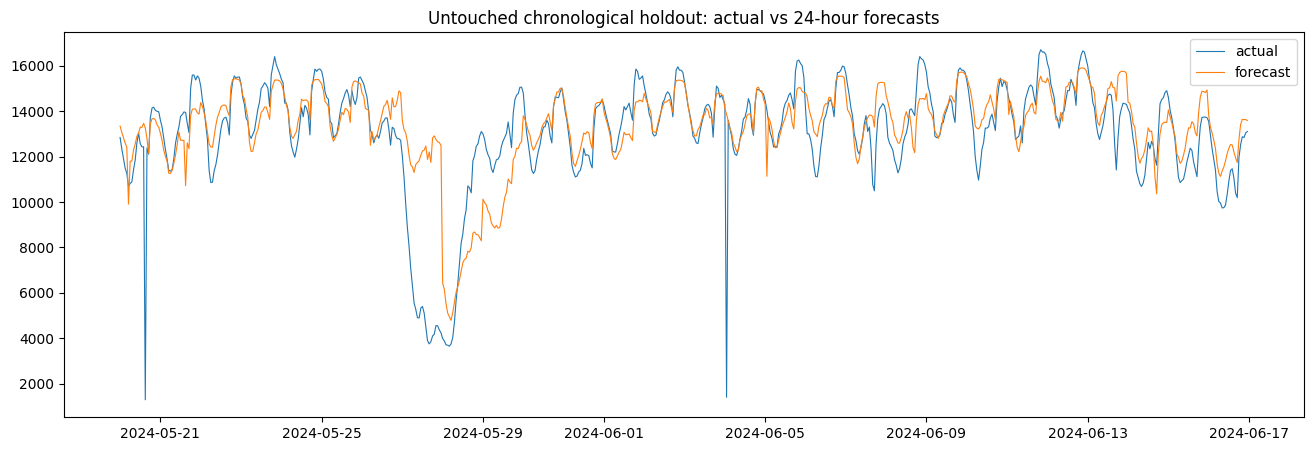

In [19]:
first_holdout = holdout_origins[0]
train_holdout = samples.loc[samples["target_ts"] <= first_holdout].copy()
holdout_df = samples.loc[samples["origin_ts"].isin(holdout_origins)].copy()

# Fit selected supervised models on pre-holdout data only. Baselines remain valid fallbacks.
BASELINE_COLUMNS = {
    "seasonal_week": "y__same_hour_lastweek",
    "seasonal_day": "y__same_hour_yesterday",
    "baseline_blend": None,
}

def predict_named_candidate(name, frame, fitted_models=None):
    if name == "seasonal_week":
        return np.maximum(0.0, frame["y__same_hour_lastweek"].to_numpy(float))
    if name == "seasonal_day":
        return np.maximum(0.0, frame["y__same_hour_yesterday"].to_numpy(float))
    if name == "baseline_blend":
        return np.maximum(0.0, 0.5*frame["y__same_hour_yesterday"].to_numpy(float) + 0.5*frame["y__same_hour_lastweek"].to_numpy(float))
    model, used = fitted_models[name]
    return predict_candidate(model, used, frame)

final_holdout_models={}
for name, weight in ensemble_weights.items():
    if name in BASELINE_COLUMNS:
        continue
    if name == "lgbm_tuned":
        algo, kind, params = "lgbm", tuned_kind, tuned_params
    else:
        algo, kind = CANDIDATES[name]
        params = None
    model, used = fit_candidate(algo, feature_list(kind), train_holdout, params=params)
    final_holdout_models[name]=(model,used)

holdout_pred = holdout_df[["origin_ts","target_ts","horizon","y"]].copy()
holdout_pred["y_pred"] = 0.0
for name, weight in ensemble_weights.items():
    holdout_pred["y_pred"] += weight*predict_named_candidate(name, holdout_df, final_holdout_models)

holdout_metrics=forecast_metrics(holdout_pred.y,holdout_pred.y_pred)
print("FINAL HOLDOUT METRICS:", holdout_metrics)

# Forecast-specific diagnostics: hourly horizon, daily peak, daily energy.
horizon_report=(holdout_pred.groupby("horizon").apply(lambda g: pd.Series(forecast_metrics(g.y,g.y_pred))).reset_index())
print("Horizon-wise errors:")
display(horizon_report)

daily = holdout_pred.groupby("origin_ts").agg(actual_daily_energy=("y","sum"),pred_daily_energy=("y_pred","sum"),actual_peak=("y","max"),pred_peak=("y_pred","max"))
daily["energy_abs_error"]=(daily.pred_daily_energy-daily.actual_daily_energy).abs()
daily["peak_abs_error"]=(daily.pred_peak-daily.actual_peak).abs()
print("Daily energy MAE:", daily.energy_abs_error.mean())
print("Daily peak MAE:", daily.peak_abs_error.mean())

fig,ax=plt.subplots(figsize=(16,5))
ax.plot(holdout_pred.target_ts,holdout_pred.y,label="actual",lw=.8)
ax.plot(holdout_pred.target_ts,holdout_pred.y_pred,label="forecast",lw=.8)
ax.set_title("Untouched chronological holdout: actual vs 24-hour forecasts")
ax.legend(); plt.show()

## 18. Residual calibration for p10/p90 intervals
Intervals are calibrated from rolling out-of-time residuals, separately by horizon. Report coverage and average width together; a trivially wide interval is not useful. The same calibrated residual offsets are then applied to the untouched holdout and final forecast.

In [ ]:
# Residuals from model-selection CV predictions; model blend is fixed using CV only.
oof_cal = wide[["origin_ts","target_ts","horizon","y","y_pred_selected"]].copy()
oof_cal["resid"] = oof_cal["y"] - oof_cal["y_pred_selected"]

pooled_q10 = float(oof_cal["resid"].quantile(0.10))
pooled_q90 = float(oof_cal["resid"].quantile(0.90))
calibration = {}
for h in range(1,25):
    g=oof_cal.loc[oof_cal.horizon==h,"resid"].dropna()
    if len(g)>=30:
        calibration[h]=(float(g.quantile(.10)),float(g.quantile(.90)),len(g))
    else:
        calibration[h]=(pooled_q10,pooled_q90,len(g))

holdout_pred["p10"] = [max(0.0, p+calibration[int(h)][0]) for p,h in zip(holdout_pred.y_pred,holdout_pred.horizon)]
holdout_pred["p90"] = [max(p10, p+calibration[int(h)][1]) for p,p10,h in zip(holdout_pred.y_pred,holdout_pred.p10,holdout_pred.horizon)]
coverage = ((holdout_pred.y>=holdout_pred.p10)&(holdout_pred.y<=holdout_pred.p90)).mean()
interval_width = (holdout_pred.p90-holdout_pred.p10).mean()
print(f"Holdout empirical 80% interval coverage: {coverage:.3f}")
print(f"Holdout mean interval width: {interval_width:.3f} MW")
print("Coverage/width must be judged together; do not call an interval calibrated if coverage is poor.")

## 19. Train the final model using every label available before the requested forecast origin

In [ ]:
final_train = samples.loc[samples["target_ts"] <= forecast_origin].copy()
if final_train["origin_ts"].nunique() < 180:
    raise ValueError("Fewer than 180 usable daily forecast origins remain before the requested date. Use more history or review missing/outlier masking.")

final_models={}
for name, weight in ensemble_weights.items():
    if name in BASELINE_COLUMNS:
        continue
    if name == "lgbm_tuned":
        algo, kind, params = "lgbm", tuned_kind, tuned_params
    else:
        algo, kind = CANDIDATES[name]
        params = None
    model,used=fit_candidate(algo,feature_list(kind),final_train,params=params)
    final_models[name]=(model,used)

future_rows = pd.DataFrame(make_origin_rows(forecast_origin, include_y=False))
future_rows["y_pred"] = 0.0
for name,weight in ensemble_weights.items():
    future_rows["y_pred"] += weight*predict_named_candidate(name, future_rows, final_models)

future_rows["p10"]=[max(0.0,p+calibration[int(h)][0]) for p,h in zip(future_rows.y_pred,future_rows.horizon)]
future_rows["p90"]=[max(lo,p+calibration[int(h)][1]) for p,lo,h in zip(future_rows.y_pred,future_rows.p10,future_rows.horizon)]

submission = future_rows[["target_ts","y_pred","p10","p90"]].rename(columns={"target_ts":"timestamp","y_pred":"demand_mw"})
submission["timestamp"] = pd.to_datetime(submission["timestamp"]).dt.strftime("%Y-%m-%d %H:%M:%S")
submission = submission[["timestamp","demand_mw","p10","p90"]]
assert len(submission)==24 and submission["timestamp"].is_unique
assert (submission["p10"]<=submission["demand_mw"]).all() and (submission["demand_mw"]<=submission["p90"]).all()

submission_path=OUTPUT_DIR/"sample_forecast_one_origin.csv"
submission.to_csv(submission_path,index=False)
print("Saved:",submission_path)
display(submission)

## 20. Export full evaluation artefacts
Keep the outlier audit and validation report with the forecast. This makes the result reproducible and gives judges/reviewers enough context to assess model quality.

In [ ]:
# Save anomaly candidates, model tables, fold predictions, holdout predictions and forecast.
anomaly_path=OUTPUT_DIR/"data_anomaly_audit.csv"
anomaly_table.loc[extreme_high | invalid_negative | zero_or_nonpositive].to_csv(anomaly_path)
cv_leaderboard.to_csv(OUTPUT_DIR/"rolling_cv_leaderboard.csv")
oof_leaderboard.to_csv(OUTPUT_DIR/"oof_leaderboard.csv",index=False)
cv_predictions.to_csv(OUTPUT_DIR/"rolling_cv_predictions.csv",index=False)
holdout_pred.to_csv(OUTPUT_DIR/"final_holdout_predictions.csv",index=False)
horizon_report.to_csv(OUTPUT_DIR/"horizon_error_report.csv",index=False)
daily.to_csv(OUTPUT_DIR/"daily_peak_energy_report.csv")

run_metadata={
    "dataset_url":DATA_URL,
    "git_blob_sha":git_blob_sha,
    "rows_raw":int(len(raw)),
    "full_hour_slots":int(len(hourly)),
    "missing_hour_slots":int(len(missing_hours)),
    "first_timestamp":str(hourly.index.min()),
    "last_timestamp":str(hourly.index.max()),
    "forecast_date":str(forecast_day.date()),
    "forecast_origin":str(forecast_origin),
    "selected_models":ensemble_weights,
    "cv_metrics":forecast_metrics(oof_cal.y,oof_cal.y_pred_selected),
    "holdout_metrics":holdout_metrics,
    "holdout_interval_coverage_80":float(coverage),
    "holdout_mean_interval_width_mw":float(interval_width),
    "python":platform.python_version(),
    "pandas":pd.__version__,
}
(OUTPUT_DIR/"run_metadata.json").write_text(json.dumps(run_metadata,indent=2))

print("Output files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

## 21. Research interpretation checklist

Before presenting the result, answer these questions from the notebook outputs:

1. Does the chosen model beat **both** seasonal-naïve baselines on the untouched holdout?
2. Does adding historical generation/fuel/import context beat the demand-only feature set? If not, use the simpler demand-only model.
3. Are the 24 horizon errors reasonably stable, or does accuracy deteriorate at longer horizons?
4. Is there systematic bias (forecast consistently too high or too low)?
5. Are peak-demand errors materially worse than average-hour errors?
6. Do the p10/p90 intervals achieve useful empirical coverage without being excessively wide?
7. Are model gains consistent across all rolling folds, or driven by one period?
8. Did any data-quality anomaly or missing block coincide with unusually large errors?
9. Do any operational covariate features appear suspiciously powerful? Confirm they are lagged and were known by the issue time.
10. Can the exact forecast date be reproduced from the saved configuration and dataset SHA?

### Recommended paper-quality reporting

Report the dataset version/hash, timestamp audit, outlier policy, forecast origin convention, model feature availability, fold dates, untouched holdout dates, MAE, RMSE, WAPE, bias, peak MAE, interval coverage and interval width. State all limitations. Avoid claiming “near-perfect” accuracy or “SOTA” based solely on a single split.

## 22. Optional TimesFM note — do not ignore model licensing

Google announced TimesFM-3 in August 2026 and reports strong multivariate forecasting benchmark results. However, the current downloadable TimesFM-3 checkpoint weights are distributed under a **non-commercial license**; this is not suitable as a dependency for a revenue-generating GRIDTWIN-24 product unless the relevant rights are separately obtained. The code and older TimesFM checkpoints have different licensing terms. Check the exact model-card license before any deployment.

Chronos-2 is included as the optional foundation-model challenger because the current Amazon implementation documents quantile output and past/future covariate interfaces, and the project reports an Apache-2.0 license. Model performance must still be measured on this dataset; benchmark rankings elsewhere do not guarantee local superiority.

## References and provenance

- Dataset repository README: https://github.com/CodewithJha/hack-day-lucknow-datasets/tree/main/p2-grid-demand-forecast
- Chronos-2 implementation and usage: https://github.com/amazon-science/chronos-forecasting
- Chronos-2 pipeline API: https://github.com/amazon-science/chronos-forecasting/blob/main/src/chronos/chronos2/pipeline.py
- TimesFM-3 announcement: https://research.google/blog/timesfm-3-a-zero-shot-foundation-model-for-multivariate-forecasting/
- TimesFM license notice: https://github.com/google-research/timesfm
- Forecast evaluation pitfalls and leakage: https://pmc.ncbi.nlm.nih.gov/articles/PMC9718476/
- Rolling-origin evaluation technique: https://alan-turing-institute.github.io/tea-techniques/techniques/rolling-origin-evaluation/

**Reproducibility note:** Package versions and dataset commit may change. Record the installed package versions and dataset SHA in the final experiment report. The notebook is an experimental pipeline, not a guarantee of any particular error rate.

## 23. Save Model Package to Google Drive for UI Integration
This cell mounts Google Drive and serializes your trained models, validation weights, and calibration parameters to a single file. You can load this file directly in your UI application later.

In [23]:
import joblib
from google.colab import drive

# 1. Mount Google Drive
try:
    print("Mounting Google Drive...")
    drive.mount('/content/drive')

    # 2. Define the path inside Google Drive
    drive_output_dir = Path("/content/drive/MyDrive/gridtwin24_model")
    drive_output_dir.mkdir(parents=True, exist_ok=True)
    model_save_path = drive_output_dir / "trained_model_package.joblib"

    # 3. Package the final models, calibration offsets, and ensemble weights
    model_package = {
        "models": final_models,
        "ensemble_weights": ensemble_weights,
        "calibration": calibration,
        "features": {
            "base": BASE_FEATURES,
            "context": CONTEXT_FEATURES,
            "candidates": CANDIDATES
        }
    }

    # 4. Save to Google Drive
    joblib.dump(model_package, model_save_path)
    print(f"\nSuccess! Model package saved successfully to Google Drive:")
    print(model_save_path)

except Exception as e:
    print(f"\nError saving model package to Google Drive: {e}")
    print("Make sure you grant permission to mount Google Drive when prompted.")

Mounting Google Drive...

Error saving model package to Google Drive: mount failed
Make sure you grant permission to mount Google Drive when prompted.
